# TripAdvisor ratings

The paper evaluates on hotel reviews from [Nour-Nassar/Datasets](https://github.com/Nour-Nassar/Datasets). The local `texts.rar` is that `TripAdvisor/Texts.rar` archive.

Each review has an overall rating and seven criteria: Value, Rooms, Location, Cleanliness, Check-in/front desk, Service, and Business service. A row is kept only when all eight ratings are in 1..5. Missing marks (`-1`) drop the row. That filter is what produces Table 1 (81,085 ratings, 72,119 users, 1,850 hotels).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import CRITERIA, load_ratings, make_folds, parse_hotel_text, read_archive_member


## Table 1

In [2]:
ratings = load_ratings(ROOT / 'texts.rar')
paper = {'ratings': 81085, 'users': 72119, 'hotels': 1850}
actual = {'ratings': len(ratings), 'users': ratings.n_users, 'hotels': ratings.n_items}
print(f'{'field':<10} {'paper':>10} {'loaded':>10}')
for key in paper:
    print(f'{key:<10} {paper[key]:>10} {actual[key]:>10}')


field           paper     loaded
ratings         81085      81085
users           72119      72119
hotels           1850       1850


## Table 2

Counts of each score from 1 to 5. The criteria matrix is stored in the paper's order, after the overall rating.

In [3]:
import numpy as np

def counts(column):
    return [(column == score).sum() for score in range(1, 6)]

header = ' '.join(f'{score:>8}' for score in range(1, 6))
print(f'{'aspect':<16}{header}')
for index, name in enumerate(CRITERIA):
    row = ' '.join(f'{n:>8}' for n in counts(ratings.criteria[:, index]))
    print(f'{name:<16}{row}')
overall = ' '.join(f'{n:>8}' for n in counts(ratings.overall))
print(f'{'overall':<16}{overall}')
print('ratings per user', len(ratings) / ratings.n_users)
print('ratings per hotel', len(ratings) / ratings.n_items)


aspect                 1        2        3        4        5
value               4268     5853    10374    24696    35894
rooms               4002     5517    10493    25019    36054
location            1464     3141     8503    22177    45800
cleanliness         2591     3585     8232    19951    46726
checkin             3775     4468    11083    19201    42558
service             4086     4462    10036    20114    42387
business            4525     5849    19624    21661    29426
overall             4246     6052     8078    24180    38529
ratings per user 1.1243223006419945
ratings per hotel 43.82972972972973


## One hotel file

`hothearted` rated only the overall score, so that review is dropped. `ozzykat` rated every aspect and is kept.

In [4]:
text = read_archive_member(ROOT / 'texts.rar', 'Texts/Texts/hotel_100504_parsed.txt')
rows = parse_hotel_text(text, '100504')
authors = {row[0] for row in rows}
print('complete reviews in this file', len(rows))
print('ozzykat kept', 'ozzykat' in authors)
print('hothearted kept', 'hothearted' in authors)
print('first kept row', rows[0][0], rows[0][2])


complete reviews in this file 52
ozzykat kept True
hothearted kept False
first kept row Chianti_girl24 (5, 5, 5, 5, 5, 5, 5, 5)


## Five folds

Ratings are shuffled. Each fold holds out 20% as test. Of the rest, 1% of all ratings is the validation slice and the remainder is the fit set.

In [5]:
folds = make_folds(len(ratings), n_folds=5, seed=42)
print(f'{'fold':<6} {'fit':>8} {'val':>8} {'test':>8}')
for index, fold in enumerate(folds):
    print(f'{index:<6} {len(fold["fit"]):>8} {len(fold["val"]):>8} {len(fold["test"]):>8}')


fold        fit      val     test
0         64057      811    16217
1         64057      811    16217
2         64057      811    16217
3         64057      811    16217
4         64057      811    16217


## Rating counts

Each panel is one aspect. The mass sits on 4 and 5, which is why a relevant item in the ranking metrics is a true rating of at least 4.

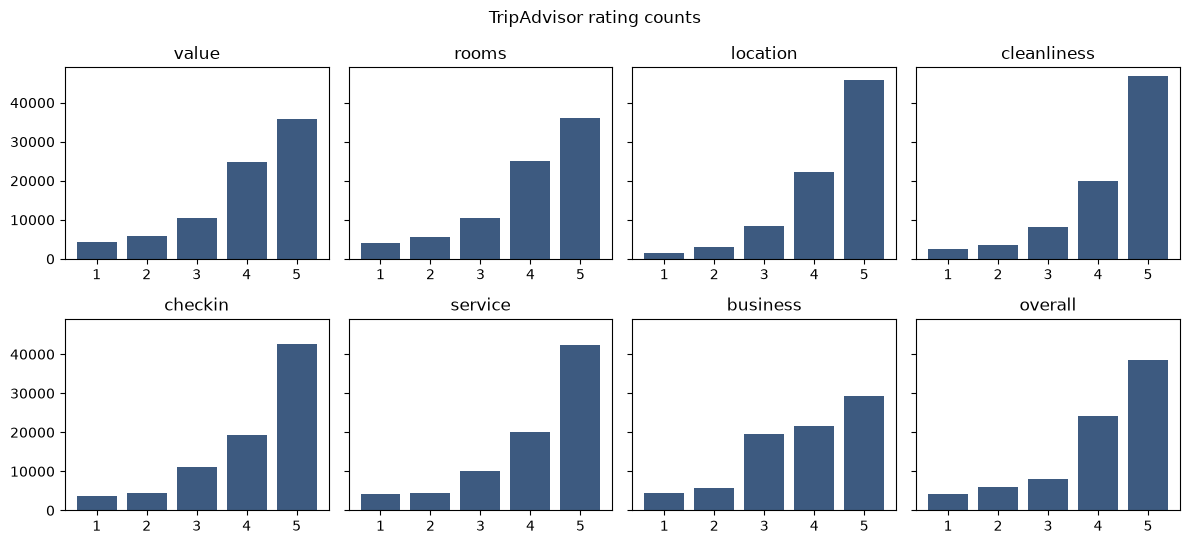

In [6]:
import matplotlib.pyplot as plt
import numpy as np

figures = ROOT / 'results' / 'figures'
figures.mkdir(parents=True, exist_ok=True)
scores = np.arange(1, 6)
series = [(name, ratings.criteria[:, index]) for index, name in enumerate(CRITERIA)]
series.append(('overall', ratings.overall))
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharey=True)
for ax, (name, column) in zip(axes.ravel(), series):
    counts = [(column == score).sum() for score in scores]
    ax.bar(scores, counts, color='#3d5a80')
    ax.set_title(name)
    ax.set_xticks(scores)
fig.suptitle('TripAdvisor rating counts')
fig.tight_layout()
fig.savefig(figures / 'rating_counts.png', dpi=150)
plt.show()
